# BANKING – CUSTOMER TRANSACTION PREDICTION

## 1. Project Introduction

This project focuses on predicting customer transaction behaviour
using Machine Learning techniques.

The objective is to develop a classification model that can
identify whether a customer will make a specific transaction
in the future based on anonymized numerical features.

The project involves data analysis, data preprocessing,
visualization, model development and performance evaluation.

## 2. Problem Statement

Banks and financial institutions generate large amounts of
customer transaction data.

Understanding customer transaction behaviour can help
financial institutions improve customer analysis and
decision-making.

The objective of this project is to build a predictive
Machine Learning model that classifies customers into
two categories:

- 0 – Customer does not make the specified transaction.
- 1 – Customer makes the specified transaction.

This is a Binary Classification problem.

## 3. Importing Required Libraries

In this section, we import the Python libraries required
for data manipulation, numerical calculations, data
visualization and Machine Learning.

Libraries used:

- Pandas: Data manipulation and analysis.
- NumPy: Numerical computations.
- Matplotlib: Data visualization.
- Seaborn: Statistical visualization.

In [5]:
# Importing required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


## 4. Loading the Dataset

In this section, we load the customer transaction dataset
into a Pandas DataFrame.

The dataset is stored in CSV format and contains anonymized
customer features along with a target variable.

We will use the training dataset for our analysis
and predictive modelling.

In [6]:
# Loading the dataset

df = pd.read_csv("Data/train(1).csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


## 5. Data Understanding

Data understanding is the initial stage of data analysis.

In this section, we examine the structure and contents
of the dataset to understand the available information.

We will inspect the first few records, dataset dimensions,
column names, data types and statistical properties.

### 5.1 Displaying the First Five Records

The head() function displays the first five rows
of the dataset.

It helps us understand the structure of the data
and identify the different columns available.

In [15]:
df.head()

,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,train_0,0,8.9255,-6.7863,11.9081,5.0930,11.4607,-9.2834,5.1187,18.6266,...,4.4354,3.9642,3.1364,1.6910,18.5227,-2.3978,7.8784,8.5635,12.7803,-1.0914
1,train_1,0,11.5006,-4.1473,13.8588,5.3890,12.3622,7.0433,5.6208,16.5338,...,7.6421,7.7214,2.5837,10.9516,15.4305,2.0339,8.1267,8.7889,18.3560,1.9518
2,train_2,0,8.6093,-2.7457,12.0805,7.8928,10.5825,-9.0837,6.9427,14.6155,...,2.9057,9.7905,1.6704,1.6858,21.6042,3.1417,-6.5213,8.2675,14.7222,0.3965
3,train_3,0,11.0604,-2.1518,8.9522,7.1957,12.5846,-1.8361,5.8428,14.9250,...,4.4666,4.7433,0.7178,1.4214,23.0347,-1.2706,-2.9275,10.2922,17.9697,-8.9996
4,train_4,0,9.8369,-1.4834,12.8746,6.6375,12.2772,2.4486,5.9405,19.2514,...,-1.4905,9.5214,-0.1508,9.1942,13.2876,-1.5121,3.9267,9.5031,17.9974,-8.8104


### 5.2 Checking Dataset Dimensions

The shape attribute provides the total number of rows
and columns present in the dataset.

Rows represent customer records, while columns represent
different features and the target variable.

In [16]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 200000
Number of columns: 202


### 5.3 Checking Column Names

In this section, we display all the column names
available in the dataset.

This helps us identify the ID column, independent
variables and target variable.

In [17]:
print(df.columns.tolist())

['ID_code', 'target', 'var_0', 'var_1', 'var_2', 'var_3', 'var_4', 'var_5', 'var_6', 'var_7', 'var_8', 'var_9', 'var_10', 'var_11', 'var_12', 'var_13', 'var_14', 'var_15', 'var_16', 'var_17', 'var_18', 'var_19', 'var_20', 'var_21', 'var_22', 'var_23', 'var_24', 'var_25', 'var_26', 'var_27', 'var_28', 'var_29', 'var_30', 'var_31', 'var_32', 'var_33', 'var_34', 'var_35', 'var_36', 'var_37', 'var_38', 'var_39', 'var_40', 'var_41', 'var_42', 'var_43', 'var_44', 'var_45', 'var_46', 'var_47', 'var_48', 'var_49', 'var_50', 'var_51', 'var_52', 'var_53', 'var_54', 'var_55', 'var_56', 'var_57', 'var_58', 'var_59', 'var_60', 'var_61', 'var_62', 'var_63', 'var_64', 'var_65', 'var_66', 'var_67', 'var_68', 'var_69', 'var_70', 'var_71', 'var_72', 'var_73', 'var_74', 'var_75', 'var_76', 'var_77', 'var_78', 'var_79', 'var_80', 'var_81', 'var_82', 'var_83', 'var_84', 'var_85', 'var_86', 'var_87', 'var_88', 'var_89', 'var_90', 'var_91', 'var_92', 'var_93', 'var_94', 'var_95', 'var_96', 'var_97', 'var_98'

### 5.4 Checking Dataset Information

The info() function provides information about:

- Column names
- Data types
- Non-null values
- Memory usage

This helps us understand the overall structure
and quality of the dataset.

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Columns: 202 entries, ID_code to var_199
dtypes: float64(200), int64(1), object(1)
memory usage: 308.2+ MB


### 5.5 Statistical Summary

The describe() function provides statistical
information about numerical columns.

It includes:

- Mean
- Standard deviation
- Minimum and maximum values
- 25th, 50th and 75th percentiles

This helps us understand the distribution
and range of numerical features.

In [19]:
df.describe()

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
count,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,...,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000
mean,0.100490,10.679914,-1.627622,10.715192,6.796529,11.078333,-5.065317,5.408949,16.545850,0.284162,...,3.234440,7.438408,1.927839,3.331774,17.993784,-0.142088,2.303335,8.908158,15.870720,-3.326537
std,0.300653,3.040051,4.050044,2.640894,2.043319,1.623150,7.863267,0.866607,3.418076,3.332634,...,4.559922,3.023272,1.478423,3.992030,3.135162,1.429372,5.454369,0.921625,3.010945,10.438015
min,0.000000,0.408400,-15.043400,2.117100,-0.040200,5.074800,-32.562600,2.347300,5.349700,-10.505500,...,-14.093300,-2.691700,-3.814500,-11.783400,8.694400,-5.261000,-14.209600,5.960600,6.299300,-38.852800
25%,0.000000,8.453850,-4.740025,8.722475,5.254075,9.883175,-11.200350,4.767700,13.943800,-2.317800,...,-0.058825,5.157400,0.889775,0.584600,15.629800,-1.170700,-1.946925,8.252800,13.829700,-11.208475
50%,0.000000,10.524750,-1.608050,10.580000,6.825000,11.108250,-4.833150,5.385100,16.456800,0.393700,...,3.203600,7.347750,1.901300,3.396350,17.957950,-0.172700,2.408900,8.888200,15.934050,-2.819550
75%,0.000000,12.758200,1.358625,12.516700,8.324100,12.261125,0.924800,6.003000,19.102900,2.937900,...,6.406200,9.512525,2.949500,6.205800,20.396525,0.829600,6.556725,9.593300,18.064725,4.836800
max,1.000000,20.315000,10.376800,19.353000,13.188300,16.671400,17.251600,8.447700,27.691800,10.151300,...,18.440900,16.716500,8.402400,18.281800,27.928800,4.272900,18.321500,12.000400,26.079100,28.500700


### 5.6 Checking Missing Values

Missing values are observations where data is not available.

In this section, we calculate the total number of missing
values in the dataset.

This helps us determine whether any missing-value
treatment is required before model development.

In [20]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


### 5.7 Checking Duplicate Records

Duplicate records are repeated observations
in the dataset.

We use the duplicated() function to identify
the total number of duplicate rows.

This helps maintain data quality and reliability.

In [21]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


## 6. Data Cleaning

Data cleaning is the process of identifying and handling
unnecessary, incorrect or inconsistent data.

It helps improve the quality and reliability of the dataset
before performing Exploratory Data Analysis and Machine Learning.

### 6.1 Checking Unique Values

In this section, we calculate the number of unique values
present in each column.

This helps us understand the variation of values
within different features.

In [22]:
# Checking unique values in each column

df.nunique()

ID_code    200000
target          2
var_0       94672
var_1      108932
var_2       86555
            ...  
var_195     57870
var_196    125560
var_197     40537
var_198     94153
var_199    149430
Length: 202, dtype: int64

### 6.2 Checking Target Variable Values

The target variable contains the output classes
that our Machine Learning model will predict.

We check its unique values to confirm that
the problem involves binary classification.

In [23]:
print("Unique target values:", df['target'].unique())

Unique target values: [0 1]


### 6.3 Checking the ID Column

The ID_code column is used to identify individual records.

Since it is an identification variable rather than
a meaningful predictive feature, we will exclude it
from model training later.

In [24]:
print("Total unique IDs:", df['ID_code'].nunique())
print("Total records:", len(df))

Total unique IDs: 200000
Total records: 200000


### 6.4 Feature-wise Missing Value Analysis

In this section, we check missing values separately
for each column.

This helps identify whether any particular feature
contains incomplete observations.

In [25]:
missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

Series([], dtype: int64)


### 6.5 Checking Constant Features

Constant features are columns that contain only one
unique value throughout the dataset.

Such features do not provide useful information
for distinguishing between target classes.

We identify these columns for further examination.

In [26]:
constant_features = [
    col for col in df.columns
    if df[col].nunique() <= 1
]

print("Constant features:", constant_features)
print("Number of constant features:", len(constant_features))

Constant features: []
Number of constant features: 0


### 6.6 Final Data Quality Check

After performing the initial data cleaning checks,
we examine the dataset dimensions and data quality
to ensure that it is ready for Exploratory Data Analysis.

In [27]:
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Constant features:", len(constant_features))

Dataset shape: (200000, 202)
Missing values: 0
Duplicate rows: 0
Constant features: 0


## 7. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand
the structure, distribution and relationships within
the dataset.

It helps identify patterns, trends and unusual observations
that may influence the Machine Learning model.

In this section, we will analyse the target variable,
numerical feature distributions and correlations.

### 7.1 Target Variable Distribution

The target variable represents the transaction behaviour
of customers.

- 0 indicates that the customer does not make the specified transaction.
- 1 indicates that the customer makes the specified transaction.

We analyse the frequency of both classes to understand
the distribution of customer transactions.

In [28]:
# Counting target classes

target_counts = df['target'].value_counts()

print(target_counts)

target
0    179902
1     20098
Name: count, dtype: int64


### 7.2 Percentage Distribution of Target Variable

In this section, we calculate the percentage of records
belonging to each target class.

This helps us determine whether the dataset is balanced
or imbalanced.

In [29]:
target_percentage = df['target'].value_counts(normalize=True) * 100

print(target_percentage)

target
0    89.951
1    10.049
Name: proportion, dtype: float64


### 7.3 Visualization of Target Variable

A count plot is used to visualize the number of records
belonging to each target class.

This graphical representation makes it easier to compare
customers who make transactions with those who do not.

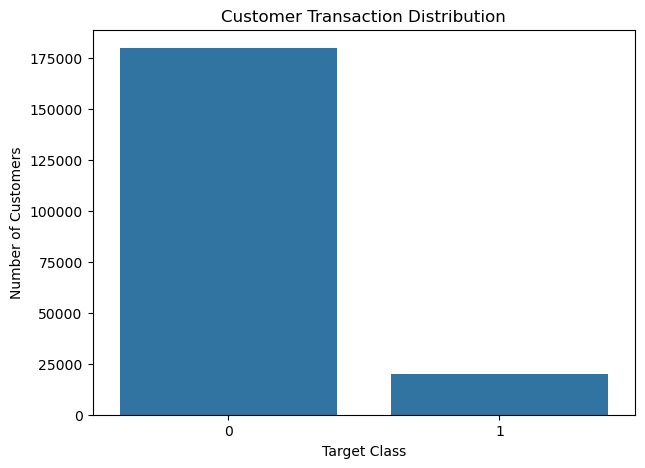

In [30]:
plt.figure(figsize=(7, 5))

sns.countplot(x='target', data=df)

plt.title('Customer Transaction Distribution')
plt.xlabel('Target Class')
plt.ylabel('Number of Customers')

plt.show()

### 7.4 Distribution of Numerical Features

The dataset contains 200 anonymized numerical features.

Histograms are used to understand how the values
of individual features are distributed.

We initially examine five selected features to
understand their distribution patterns.

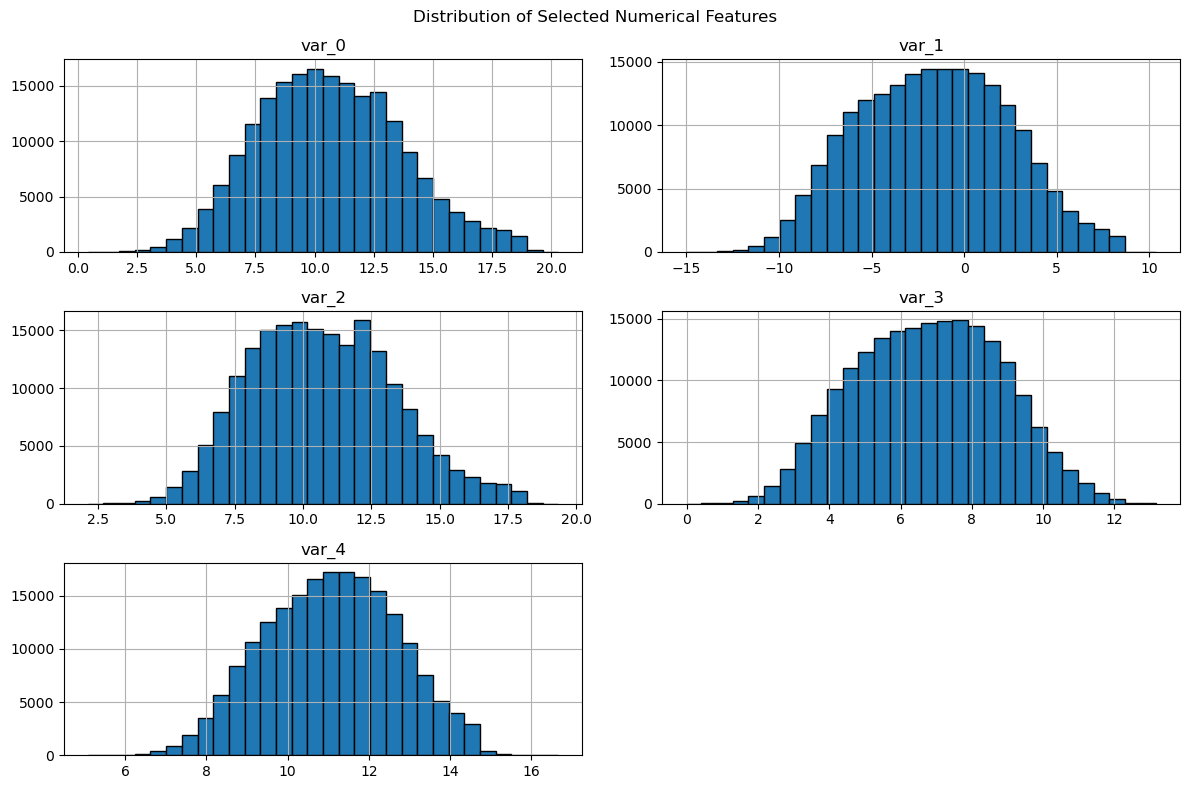

In [31]:
features = ['var_0', 'var_1', 'var_2', 'var_3', 'var_4']

df[features].hist(
    figsize=(12, 8),
    bins=30,
    edgecolor='black'
)

plt.suptitle('Distribution of Selected Numerical Features')

plt.tight_layout()
plt.show()

### 7.5 Boxplot Analysis of Numerical Features

Boxplots are used to understand the spread of numerical
data and identify potential outliers.

They display the median, quartiles and extreme observations
for selected numerical features.

We use boxplots to examine the first five features.

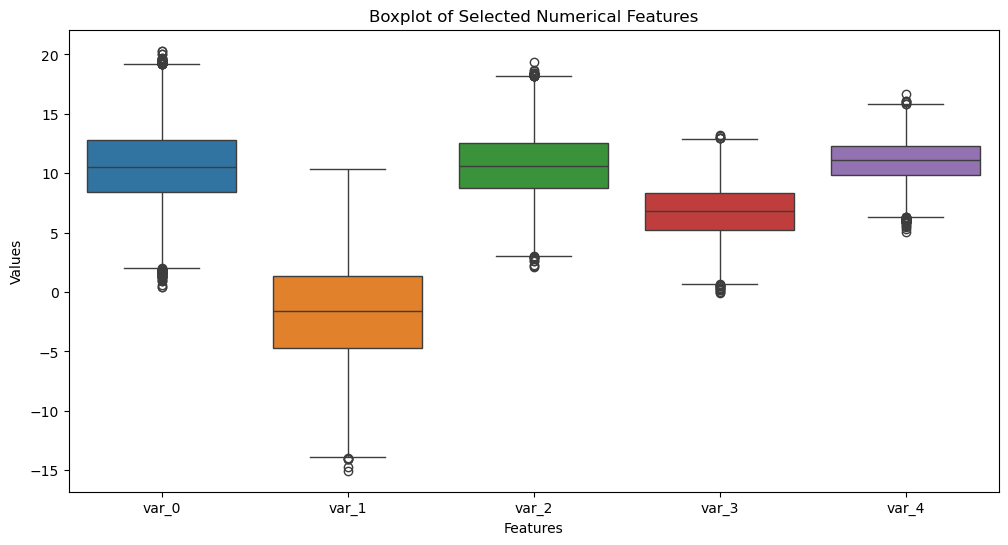

In [32]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=df[features])

plt.title('Boxplot of Selected Numerical Features')
plt.xlabel('Features')
plt.ylabel('Values')

plt.show()

### 7.6 Correlation Analysis

Correlation analysis helps us understand the relationship
between numerical variables.

The correlation coefficient ranges from -1 to +1.

- +1 indicates a perfect positive correlation.
- -1 indicates a perfect negative correlation.
- 0 indicates no linear correlation.

We calculate the correlation among ten selected features.

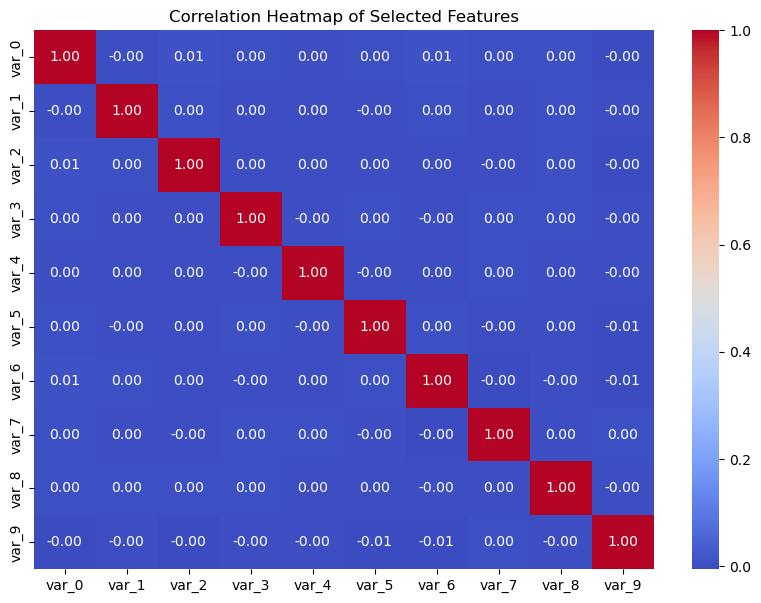

In [33]:
correlation = df[
    ['var_0', 'var_1', 'var_2', 'var_3', 'var_4',
     'var_5', 'var_6', 'var_7', 'var_8', 'var_9']
].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Selected Features')

plt.show()

### 7.7 Correlation of Features with Target Variable

In this section, we calculate the correlation between
the numerical features and the target variable.

This helps us identify which features have relatively
stronger positive or negative linear relationships
with the target variable.

We examine the ten features with the highest absolute
correlation values.

In [34]:
target_corr = (
    df.drop(columns=['ID_code'])
      .corr()['target']
      .drop('target')
)

top_correlations = target_corr.abs().sort_values(
    ascending=False
).head(10)

print("Top 10 features correlated with target:")
print(target_corr.loc[top_correlations.index])

Top 10 features correlated with target:
var_81    -0.080917
var_139   -0.074080
var_12    -0.069489
var_6      0.066731
var_110    0.064275
var_146   -0.063644
var_53     0.063399
var_26     0.062422
var_76    -0.061917
var_174   -0.061669
Name: target, dtype: float64


## 8. Data Preprocessing

Data preprocessing is an important step in Machine Learning.

It involves preparing and transforming raw data into
a suitable format for model training.

In this project, we will separate the input features
and target variable, remove unnecessary identification
columns and divide the dataset into training and testing sets.

### 8.1 Separating Independent and Dependent Variables

Independent variables (X) are the input features used
by the Machine Learning model to make predictions.

The dependent variable (y) is the target variable
that the model needs to predict.

In this dataset:
- X contains the 200 numerical features.
- y contains the target variable.

In [7]:
# Separating input features and target variable

X = df.drop(columns=['ID_code', 'target'])

y = df['target']

print("Independent variables shape:", X.shape)
print("Dependent variable shape:", y.shape)

Independent variables shape: (200000, 200)
Dependent variable shape: (200000,)


### 8.2 Checking Target Class Distribution

Before splitting the dataset, we examine the distribution
of the target variable.

This helps us identify whether the dataset is imbalanced.

We will use stratified sampling during train-test splitting
to maintain approximately the same class distribution
in both datasets.

In [36]:
# Checking target class distribution

print(y.value_counts())

print("\nTarget percentage:")
print(y.value_counts(normalize=True) * 100)

target
0    179902
1     20098
Name: count, dtype: int64

Target percentage:
target
0    89.951
1    10.049
Name: proportion, dtype: float64


### 8.3 Train-Test Split

Train-test splitting divides the dataset into two parts.

- Training data: Used to train the Machine Learning model.
- Testing data: Used to evaluate the model on unseen records.

We will use an 80:20 split.

80% of the data will be used for training
and 20% will be used for testing.

Stratified sampling will preserve the target class
proportions in both sets.

In [8]:
# Importing train_test_split

from sklearn.model_selection import train_test_split

# Splitting the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training data shape: (160000, 200)
Testing data shape: (40000, 200)
Training target shape: (160000,)
Testing target shape: (40000,)


### 8.4 Feature Scaling

Feature scaling is the process of bringing numerical
features to a comparable scale.

Some Machine Learning algorithms are sensitive
to differences in feature magnitudes.

We will use StandardScaler to standardize the numerical
features.

The scaler will be fitted only on training data
to prevent data leakage.

In [38]:
# Importing StandardScaler

from sklearn.preprocessing import StandardScaler

# Creating scaler object

scaler = StandardScaler()

# Fitting and transforming training data

X_train_scaled = scaler.fit_transform(X_train)

# Transforming testing data

X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Feature scaling completed successfully!
Scaled training shape: (160000, 200)
Scaled testing shape: (40000, 200)


### 8.5 Final Preprocessing Verification

After completing the preprocessing operations,
we verify the dimensions of the training and testing
datasets.

This ensures that the data is ready for Machine
Learning model development.

In [39]:
print("Final Preprocessing Summary")
print("----------------------------")

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nTraining and testing datasets are ready!")

Final Preprocessing Summary
----------------------------
X_train: (160000, 200)
X_test: (40000, 200)
y_train: (160000,)
y_test: (40000,)

Training and testing datasets are ready!


# 9. Machine Learning Model Building

Machine Learning model building is the process of training
algorithms using historical data to identify patterns
and make predictions.

In this project, we will develop classification models
to predict whether a customer will make a specific
transaction in the future.

We will train and compare different classification
algorithms to identify the most suitable model.

The models selected for this project are:

1. Logistic Regression
2. Random Forest Classifier
3. XGBoost Classifier

### 9.1 Importing Machine Learning Algorithms

In this section, we import the classification algorithms
required for model development.

Logistic Regression is used as a baseline classification
algorithm, while Random Forest and XGBoost are ensemble
learning algorithms that can capture more complex patterns.

In [40]:
# Importing classification algorithms

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

print("Machine Learning algorithms imported successfully!")

Machine Learning algorithms imported successfully!


### 9.2 Logistic Regression Model

Logistic Regression is a supervised Machine Learning
algorithm used for classification problems.

It estimates the probability of an observation
belonging to a particular class.

In this project, it will predict whether a customer
will make a transaction (1) or will not make a
transaction (0).

We use scaled training data to train the model.
Class weighting is applied to help address the
unequal distribution of target classes.

In [41]:
# Creating Logistic Regression model

log_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

# Training the model

log_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


### 9.3 Making Predictions Using Logistic Regression

After training the Logistic Regression model, we use
the testing dataset to generate predictions.

The model predicts the transaction status of customers
based on their input features.

The predicted values represent:

- 0: Customer will not make the transaction.
- 1: Customer will make the transaction.

In [42]:
# Making predictions

y_pred_log = log_model.predict(X_test_scaled)

print("Predictions generated successfully!")

print("First 20 predictions:")
print(y_pred_log[:20])

Predictions generated successfully!
First 20 predictions:
[0 0 0 0 0 0 0 1 0 0 0 0 1 0 1 0 0 0 0 1]


### 9.4 Predicting Transaction Probabilities

Apart from predicting the final class, Logistic Regression
can also calculate the probability of a customer making
a transaction.

The predict_proba() function returns the probability
of belonging to each target class.

We examine the probability of class 1, which represents
the likelihood of a customer making the transaction.

In [43]:
# Predicting probabilities

y_prob_log = log_model.predict_proba(X_test_scaled)[:, 1]

print("First 10 transaction probabilities:")
print(y_prob_log[:10])

First 10 transaction probabilities:
[0.03897576 0.38678525 0.05690248 0.11077296 0.17446485 0.25554185
 0.30742267 0.64981564 0.08232744 0.19966885]


# 10. Random Forest Classification

Random Forest is a supervised Machine Learning algorithm
used for classification and regression problems.

It is an ensemble learning technique that combines
multiple decision trees to produce a final prediction.

Each decision tree makes its own prediction, and
the Random Forest model uses majority voting to
determine the final classification.

In this project, Random Forest will be used to predict
whether customers will make a future transaction.

### 10.1 Creating the Random Forest Model

In this section, we initialize the Random Forest
Classifier with selected hyperparameters.

We use multiple decision trees and set a fixed
random state to ensure reproducibility.

Class weighting is also applied to account for
the imbalance in the target variable.

In [44]:
# Importing Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier

# Creating Random Forest model

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_split=5,
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1
)

print("Random Forest model created successfully!")

Random Forest model created successfully!


### 10.2 Training the Random Forest Model

In this section, we train the Random Forest classifier
using the training dataset.

Random Forest is a tree-based algorithm, so feature
scaling is not necessary.

Therefore, we use the original unscaled training data.

The model learns patterns from the input features
and their corresponding target values.

In [45]:
# Training Random Forest model

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


### 10.3 Making Predictions Using Random Forest

After training the model, we use the testing dataset
to predict customer transaction behaviour.

The model classifies each customer into one of
two categories:

- 0: Customer will not make the transaction.
- 1: Customer will make the transaction.

In [46]:
# Making predictions

y_pred_rf = rf_model.predict(X_test)

print("Random Forest predictions generated successfully!")

print("First 20 predictions:")
print(y_pred_rf[:20])

Random Forest predictions generated successfully!
First 20 predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0]


### 10.4 Predicting Transaction Probabilities

Random Forest can also estimate the probability
of a customer belonging to each target class.

We use predict_proba() to obtain these probabilities.

The probability of class 1 represents the estimated
likelihood of a customer making the specified transaction.

In [47]:
# Predicting probabilities

y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("First 10 transaction probabilities:")
print(y_prob_rf[:10])

First 10 transaction probabilities:
[0.40029997 0.42948845 0.32391839 0.37603666 0.41656914 0.45206127
 0.42396275 0.42293769 0.38388564 0.38494889]


# 11. XGBoost Classification

XGBoost (Extreme Gradient Boosting) is an advanced
ensemble Machine Learning algorithm.

It uses gradient boosting to combine multiple
decision trees sequentially.

Each new tree attempts to improve the predictions
by learning from the errors of previous trees.

In this project, XGBoost will be used to predict
customer transaction behaviour and will be compared
with Logistic Regression and Random Forest.

### 11.1 Importing XGBoost

In this section, we import the XGBoost classifier
required for model development.

XGBoost is a separate Python library that provides
efficient gradient boosting algorithms.

In [48]:
# Importing XGBoost

try:
    from xgboost import XGBClassifier
    print("XGBoost imported successfully!")

except ImportError:
    print("XGBoost is not installed.")
    print("Install it using: pip install xgboost")

XGBoost is not installed.
Install it using: pip install xgboost


### 11.2 Creating the XGBoost Model

In this section, we initialize the XGBoost classifier
with selected hyperparameters.

We use:
- Number of estimators: 300
- Maximum tree depth: 5
- Learning rate: 0.05
- Subsample: 0.8
- Column sampling: 0.8

We also calculate the class imbalance ratio and use
it to assign greater importance to the minority class.

In [49]:
# Calculate class imbalance ratio

scale_weight = (
    (y_train == 0).sum() / (y_train == 1).sum()
)

print("Class imbalance ratio:", scale_weight)

Class imbalance ratio: 8.95148650329643


In [50]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 2.2 MB/s eta 0:00:23
    --------------------------------------- 1.0/48.9 MB 2.1 MB/s eta 0:00:24
   - -------------------------------------- 1.3/48.9 MB 2.0 MB/s eta 0:00:24
   - -------------------------------------- 1.8/48.9 MB 2.0 MB/s eta 0:00:23
   - -------------------------------------- 2.4/48.9 MB 2.1 MB/s eta 0:00:23
   -- ------------------------------------- 2.6/48.9 MB 2.0 MB/s eta 0:00:24
   -- ------------------------------------- 3.1/48.9 MB 2.0 MB/s eta 0:00:23
   -- ------------------------------------- 3.4/48.9 MB 2.0 MB/s eta 0:00:23
   -- ------------------------------------- 3.7/48.9 MB 2.0 MB/s eta 0:00:23
   --- ------------------------------------ 4.2/48.9 MB 2.0 MB/s eta 0:00:23
   --- ------------------------------------ 4.5/48.9 MB 2.0 MB/s eta 0:00:23
   ---- -----

In [51]:
# Creating XGBoost model

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_weight,
    eval_metric='auc',
    random_state=42,
    n_jobs=-1,
    tree_method='hist'
)

print("XGBoost model created successfully!")

NameError: name 'XGBClassifier' is not defined

In [52]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [1]:
# Creating XGBoost model

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_weight,
    eval_metric='auc',
    random_state=42,
    n_jobs=-1,
    tree_method='hist'
)

print("XGBoost model created successfully!")

NameError: name 'XGBClassifier' is not defined

In [2]:
from xgboost import XGBClassifier

print("XGBoost imported successfully!")

XGBoost imported successfully!


In [3]:
scale_weight = (y_train == 0).sum() / (y_train == 1).sum()

print("Class imbalance ratio:", scale_weight)

NameError: name 'y_train' is not defined

In [9]:
# Calculating class imbalance ratio

scale_weight = (y_train == 0).sum() / (y_train == 1).sum()

print("Class imbalance ratio:", scale_weight)

Class imbalance ratio: 8.95148650329643


In [10]:
# Creating XGBoost model

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_weight,
    eval_metric='auc',
    random_state=42,
    n_jobs=-1,
    tree_method='hist'
)

print("XGBoost model created successfully!")

XGBoost model created successfully!


### 11.3 Training the XGBoost Model

In this section, we train the XGBoost classifier
using the training dataset.

The algorithm builds decision trees sequentially,
with each new tree attempting to improve the
performance of the previous trees.

We use the original unscaled training data because
XGBoost is a tree-based algorithm and does not
require feature standardization.

In [11]:
# Training XGBoost model

xgb_model.fit(X_train, y_train)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


### 11.4 Making Predictions Using XGBoost

After training the model, we use the testing dataset
to predict customer transaction behaviour.

The model classifies customers into two categories:

- 0: Customer will not make the transaction.
- 1: Customer will make the transaction.

In [12]:
# Making predictions

y_pred_xgb = xgb_model.predict(X_test)

print("XGBoost predictions generated successfully!")

print("First 20 predictions:")
print(y_pred_xgb[:20])

XGBoost predictions generated successfully!
First 20 predictions:
[0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 1 0 0]


### 11.5 Predicting Transaction Probabilities

XGBoost can also estimate the probability of a
customer belonging to each target class.

We use predict_proba() to calculate the probability
of each class.

The probability of class 1 represents the estimated
likelihood of a customer making the specified transaction.

In [13]:
# Predicting probabilities

y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

print("First 10 transaction probabilities:")
print(y_prob_xgb[:10])

First 10 transaction probabilities:
[0.2504652  0.3855735  0.10256927 0.22735739 0.45682135 0.36903557
 0.37896892 0.4117072  0.17883594 0.12922026]


## 12. Model Evaluation

Model evaluation is the process of measuring how accurately a machine learning model makes predictions on unseen data.

In this project, we will evaluate Logistic Regression, Random Forest, and XGBoost using different classification metrics.

These metrics will help us understand the correctness of predictions and the ability of each model to identify customers who make transactions.

In [14]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    average_precision_score
)

print("Evaluation metrics imported successfully!")

Evaluation metrics imported successfully!


### 12.1 Understanding Classification Evaluation Metrics

1. **Accuracy:** Measures the percentage of total predictions that are correct.

2. **Precision:** Out of all customers predicted to make a transaction, how many actually made a transaction?

3. **Recall:** Out of all customers who actually made a transaction, how many did the model correctly identify?

4. **F1-Score:** The harmonic mean of precision and recall. It balances both metrics.

5. **ROC-AUC Score:** Measures how well the model distinguishes between the two classes. A higher score generally indicates better classification ability.

6. **Average Precision:** Summarizes precision-recall performance across different classification thresholds. It is particularly useful for imbalanced datasets.

### 12.2 Logistic Regression Evaluation

We will evaluate the Logistic Regression model using the test dataset.

The evaluation will include accuracy, precision, recall, F1-score, ROC-AUC, and Average Precision.

In [15]:
print("LOGISTIC REGRESSION EVALUATION")
print("--------------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_log))

print("Precision:", precision_score(y_test, y_pred_log, zero_division=0))

print("Recall:", recall_score(y_test, y_pred_log, zero_division=0))

print("F1-Score:", f1_score(y_test, y_pred_log, zero_division=0))

print("ROC-AUC:", roc_auc_score(y_test, y_prob_log))

print("Average Precision:", average_precision_score(y_test, y_prob_log))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_log, zero_division=0))

LOGISTIC REGRESSION EVALUATION
--------------------------------


NameError: name 'y_pred_log' is not defined

### Recreating Scaled Data

Since the kernel was restarted, we need to recreate the scaled training and testing datasets before training Logistic Regression.

In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled datasets recreated successfully!")

Scaled datasets recreated successfully!


### Retraining Logistic Regression Model

We will recreate the Logistic Regression classifier and train it using the scaled training dataset.

In [18]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

log_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


### Generating Logistic Regression Predictions

The trained model will predict the target values for the unseen testing dataset.

In [19]:
y_pred_log = log_model.predict(X_test_scaled)

y_prob_log = log_model.predict_proba(X_test_scaled)[:, 1]

print("Predictions generated successfully!")

Predictions generated successfully!


In [20]:
print("LOGISTIC REGRESSION EVALUATION")
print("--------------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_log))

print("Precision:", precision_score(y_test, y_pred_log, zero_division=0))

print("Recall:", recall_score(y_test, y_pred_log, zero_division=0))

print("F1-Score:", f1_score(y_test, y_pred_log, zero_division=0))

print("ROC-AUC:", roc_auc_score(y_test, y_prob_log))

print("Average Precision:", average_precision_score(y_test, y_prob_log))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_log, zero_division=0))

LOGISTIC REGRESSION EVALUATION
--------------------------------
Accuracy: 0.7834
Precision: 0.2865416436845008
Recall: 0.7753731343283582
F1-Score: 0.4184454289166331
ROC-AUC: 0.8598998891036755
Average Precision: 0.5004371715496038

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.78      0.87     35980
           1       0.29      0.78      0.42      4020

    accuracy                           0.78     40000
   macro avg       0.63      0.78      0.64     40000
weighted avg       0.90      0.78      0.82     40000



### 12.3 Confusion Matrix – Logistic Regression

A confusion matrix helps us understand the correct and incorrect predictions made by the model.

It contains four values:

- True Positive (TP): Correctly predicted transaction cases.
- True Negative (TN): Correctly predicted non-transaction cases.
- False Positive (FP): Non-transaction cases incorrectly predicted as transactions.
- False Negative (FN): Transaction cases incorrectly predicted as non-transactions.

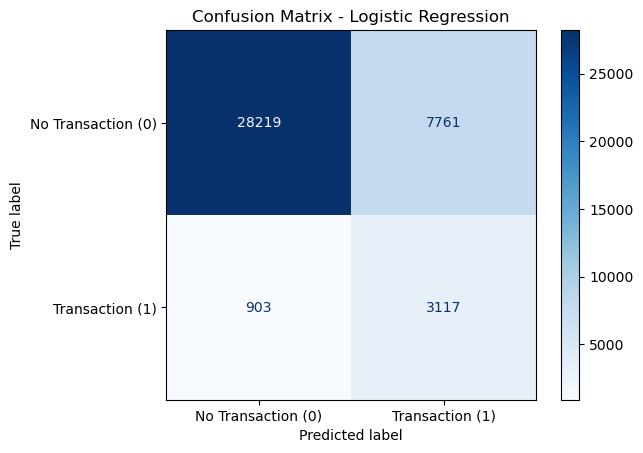

In [21]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_log,
    display_labels=['No Transaction (0)', 'Transaction (1)'],
    cmap='Blues',
    values_format='d'
)

plt.title("Confusion Matrix - Logistic Regression")
plt.show()

### 12.4 Random Forest Evaluation

In this step, we will evaluate the performance of the Random Forest Classifier using the testing dataset.

We will calculate accuracy, precision, recall, F1-score, ROC-AUC, and Average Precision to understand the model's predictive performance.

In [22]:
y_pred_rf = rf_model.predict(X_test)

y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest predictions generated successfully!")

NameError: name 'rf_model' is not defined

### 12.4 Random Forest Model Retraining

Since the Jupyter kernel was restarted, the previously trained Random Forest model is no longer available in memory.

We will recreate and train the model using the original training dataset.

In [23]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_split=5,
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1
)

print("Random Forest model created successfully!")

Random Forest model created successfully!


In [24]:
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [25]:
y_pred_rf = rf_model.predict(X_test)

y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest predictions generated successfully!")

Random Forest predictions generated successfully!


In [26]:
y_pred_rf = rf_model.predict(X_test)

y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest predictions generated successfully!")

Random Forest predictions generated successfully!


### 12.5 Random Forest Evaluation Metrics

We will calculate different classification metrics to measure how effectively the Random Forest model predicts customer transactions.

In [27]:
print("RANDOM FOREST EVALUATION")
print("--------------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_rf))

print("Precision:", precision_score(y_test, y_pred_rf, zero_division=0))

print("Recall:", recall_score(y_test, y_pred_rf, zero_division=0))

print("F1-Score:", f1_score(y_test, y_pred_rf, zero_division=0))

print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

print("Average Precision:", average_precision_score(y_test, y_prob_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

RANDOM FOREST EVALUATION
--------------------------------
Accuracy: 0.8614
Precision: 0.34537337662337664
Recall: 0.42338308457711443
F1-Score: 0.3804202056325436
ROC-AUC: 0.7925601011064742
Average Precision: 0.34474648895646215

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.91      0.92     35980
           1       0.35      0.42      0.38      4020

    accuracy                           0.86     40000
   macro avg       0.64      0.67      0.65     40000
weighted avg       0.87      0.86      0.87     40000



### 12.6 Confusion Matrix – Random Forest

A confusion matrix provides a visual representation of the correct and incorrect predictions made by the Random Forest classifier.

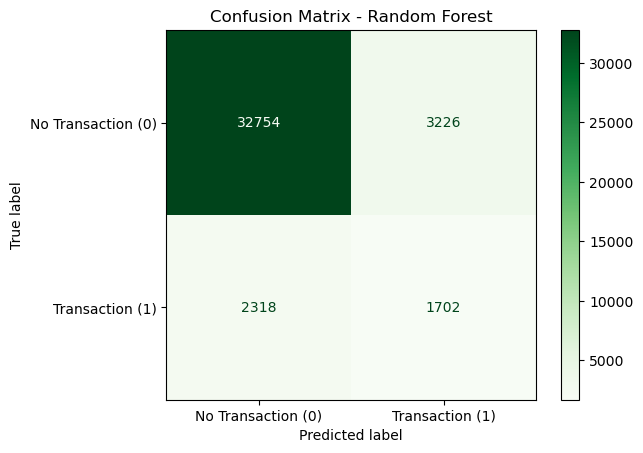

In [28]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    display_labels=['No Transaction (0)', 'Transaction (1)'],
    cmap='Greens',
    values_format='d'
)

plt.title("Confusion Matrix - Random Forest")
plt.show()

# 13. Model Comparison

In this section, we will compare the performance of Logistic Regression, Random Forest, and XGBoost.

We will use different evaluation metrics to identify which model performs best on the customer transaction prediction dataset.

The comparison will help us select the most suitable model for our classification problem.

### 13.1 Comparison of Evaluation Metrics

We will create a comparison table containing the Accuracy, Precision, Recall, F1-Score, ROC-AUC, and Average Precision scores of all three machine learning models.

In [29]:
# Creating a comparison table

model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'XGBoost'
    ],

    'Accuracy': [
        accuracy_score(y_test, y_pred_log),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_xgb)
    ],

    'Precision': [
        precision_score(y_test, y_pred_log, zero_division=0),
        precision_score(y_test, y_pred_rf, zero_division=0),
        precision_score(y_test, y_pred_xgb, zero_division=0)
    ],

    'Recall': [
        recall_score(y_test, y_pred_log, zero_division=0),
        recall_score(y_test, y_pred_rf, zero_division=0),
        recall_score(y_test, y_pred_xgb, zero_division=0)
    ],

    'F1-Score': [
        f1_score(y_test, y_pred_log, zero_division=0),
        f1_score(y_test, y_pred_rf, zero_division=0),
        f1_score(y_test, y_pred_xgb, zero_division=0)
    ],

    'ROC-AUC': [
        roc_auc_score(y_test, y_prob_log),
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_xgb)
    ],

    'Average Precision': [
        average_precision_score(y_test, y_prob_log),
        average_precision_score(y_test, y_prob_rf),
        average_precision_score(y_test, y_prob_xgb)
    ]
})

model_comparison

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Average Precision
0,Logistic Regression,0.783400,0.286542,0.775373,0.418445,0.859900,0.500437
1,Random Forest,0.861400,0.345373,0.423383,0.380420,0.792560,0.344746
2,XGBoost,0.843175,0.356880,0.698756,0.472458,0.868309,0.529055


### 13.2 Identifying the Best Performing Model

We will compare the ROC-AUC scores of all three models to identify which model has the strongest ability to distinguish between transaction and non-transaction cases.

We will also consider Average Precision because the dataset contains an imbalanced target variable.

The final model selection will be based on multiple evaluation metrics rather than accuracy alone.

In [30]:
best_model = model_comparison.loc[
    model_comparison['ROC-AUC'].idxmax()
]

print("Best Model Based on ROC-AUC:")
print(best_model)

Best Model Based on ROC-AUC:
Model                 XGBoost
Accuracy             0.843175
Precision             0.35688
Recall               0.698756
F1-Score             0.472458
ROC-AUC              0.868309
Average Precision    0.529055
Name: 2, dtype: object


# 14. Model Performance Visualization

In this section, we will visualize the performance of Logistic Regression, Random Forest, and XGBoost.

Visual comparisons will help us understand the differences in model performance and identify the most effective classifier.

### 14.1 ROC-AUC Score Comparison

We will create a bar chart to compare the ROC-AUC scores of all three machine learning models.

A higher ROC-AUC score indicates better ability to distinguish between the two target classes.

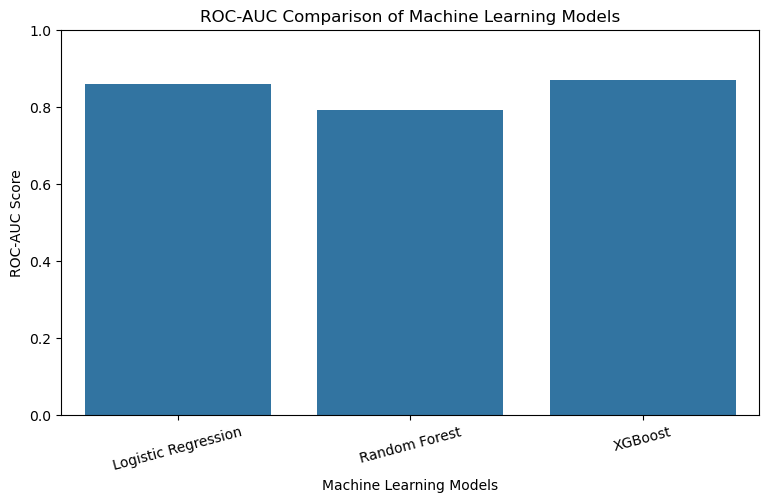

In [31]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=model_comparison,
    x='Model',
    y='ROC-AUC'
)

plt.title('ROC-AUC Comparison of Machine Learning Models')
plt.xlabel('Machine Learning Models')
plt.ylabel('ROC-AUC Score')
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.show()

### 14.2 Comparison of Classification Metrics

We will visualize Accuracy, Precision, Recall, and F1-Score to compare the classification performance of all three models.

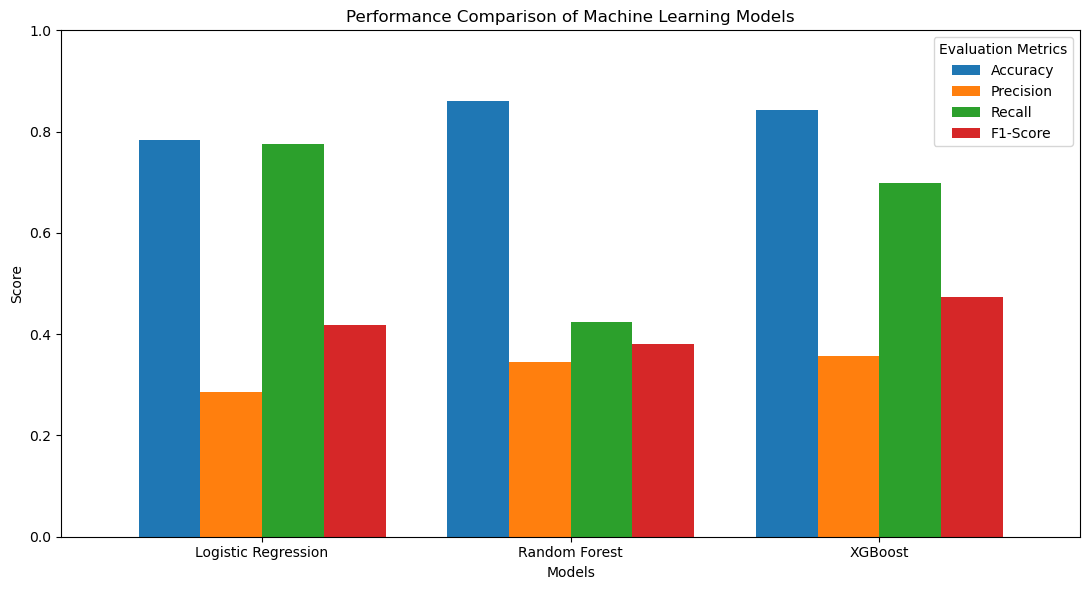

In [32]:
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

model_comparison.set_index('Model')[metrics].plot(
    kind='bar',
    figsize=(11, 6),
    width=0.8
)

plt.title('Performance Comparison of Machine Learning Models')
plt.xlabel('Models')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title='Evaluation Metrics')
plt.tight_layout()
plt.show()

# 15. ROC Curve Analysis

The Receiver Operating Characteristic (ROC) curve is used to evaluate the classification performance of machine learning models at different probability thresholds.

It plots:

- True Positive Rate (TPR) on the Y-axis.
- False Positive Rate (FPR) on the X-axis.

A curve closer to the top-left corner generally indicates better classification performance.

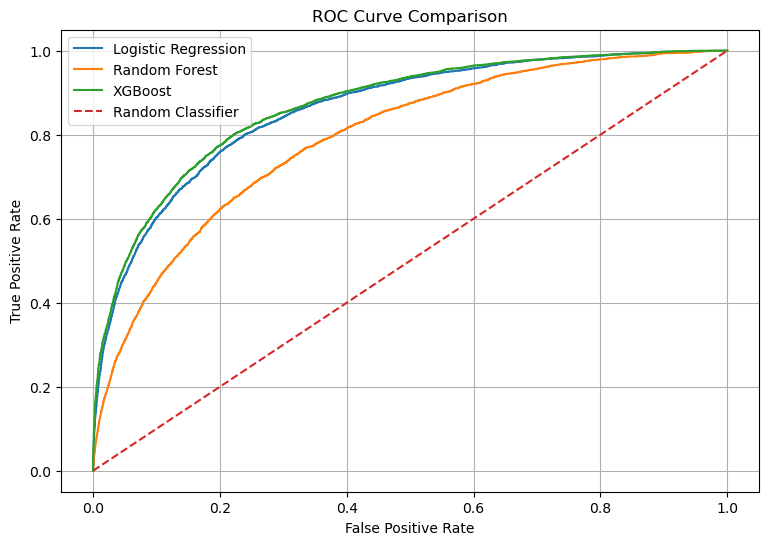

In [33]:
from sklearn.metrics import roc_curve

fpr_log, tpr_log, _ = roc_curve(y_test, y_prob_log)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)

plt.figure(figsize=(9, 6))

plt.plot(fpr_log, tpr_log, label='Logistic Regression')
plt.plot(fpr_rf, tpr_rf, label='Random Forest')
plt.plot(fpr_xgb, tpr_xgb, label='XGBoost')

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.grid()
plt.show()

# 16. Feature Importance Analysis

Feature importance analysis helps us identify which independent variables contribute most to the predictions made by a machine learning model.

In this project, we will use the feature importance values provided by XGBoost to identify the most influential features.

This analysis helps us understand the contribution of different input variables to customer transaction prediction.

### 16.1 Extracting Feature Importance Using XGBoost

XGBoost provides feature importance scores that indicate the relative contribution of different features to the model.

We will extract these scores and arrange the features in descending order of importance.

In [34]:
# Extracting feature importance from XGBoost

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': xgb_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("Top 20 Important Features:")
display(feature_importance.head(20))

Top 20 Important Features:


,Feature,Importance
81,var_81,0.024589
139,var_139,0.021600
109,var_109,0.015656
12,var_12,0.014804
53,var_53,0.014240
110,var_110,0.014020
26,var_26,0.013749
146,var_146,0.013583
44,var_44,0.013229
190,var_190,0.013119


### 16.2 Visualizing Top 20 Important Features

We will create a horizontal bar chart to visualize the top 20 most important features identified by the XGBoost model.

The chart will help us compare the relative importance of these features.

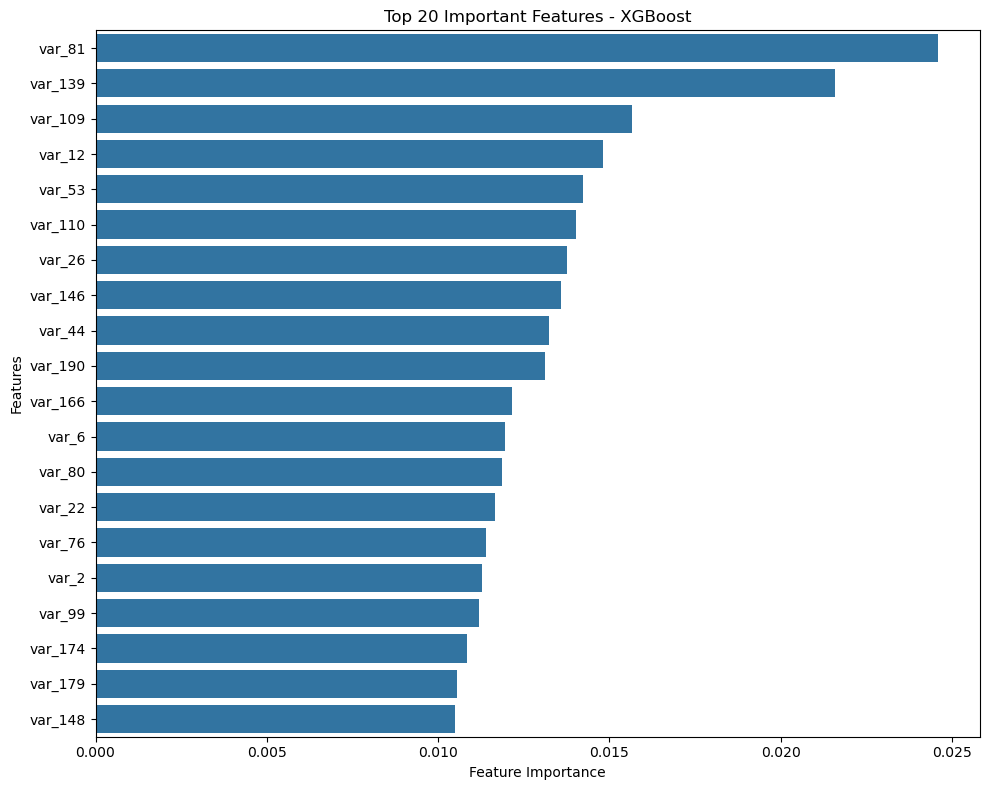

In [35]:
# Visualizing top 20 important features

top_features = feature_importance.head(20)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=top_features,
    x='Importance',
    y='Feature'
)

plt.title('Top 20 Important Features - XGBoost')
plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

### 16.3 Interpretation of Feature Importance

The feature importance graph displays the top 20 input variables that contribute most to the XGBoost model's predictions.

Features with higher importance scores have a greater contribution to the model's prediction process.

However, feature importance does not establish a causal relationship, and it does not indicate whether a feature increases or decreases the probability of a transaction.

# 17. Final Model Selection

In this section, we will select the best-performing machine learning model based on the ROC-AUC score obtained during model evaluation.

The model with the highest ROC-AUC score will be selected as the final model.

This selected model will be saved for future use.

### 17.1 Selecting the Best Performing Model

We will compare the ROC-AUC scores of Logistic Regression, Random Forest, and XGBoost to identify the best-performing classifier.

In [36]:
# Selecting the best model based on ROC-AUC

best_model_name = model_comparison.loc[
    model_comparison['ROC-AUC'].idxmax(), 'Model'
]

models = {
    'Logistic Regression': log_model,
    'Random Forest': rf_model,
    'XGBoost': xgb_model
}

best_model = models[best_model_name]

print("Selected Best Model:", best_model_name)
print(
    "Best ROC-AUC Score:",
    model_comparison['ROC-AUC'].max()
)

Selected Best Model: XGBoost
Best ROC-AUC Score: 0.868308744631484


### 17.2 Saving the Selected Model

After selecting the best-performing model, we will save it using the Joblib library.

Saving the model allows us to reuse the trained classifier without training it again.

If Logistic Regression is selected, we will also save the StandardScaler because the model requires scaled input data.

In [37]:
import joblib

# Creating a model bundle
model_bundle = {
    'model_name': best_model_name,
    'model': best_model,
    'scaler': scaler if best_model_name == 'Logistic Regression' else None
}

# Saving the model bundle
joblib.dump(
    model_bundle,
    'best_customer_transaction_model.pkl'
)

print("Best model saved successfully!")
print("Selected model:", best_model_name)

Best model saved successfully!
Selected model: XGBoost


### 17.3 Loading the Saved Model

We will load the saved model using Joblib to verify that it can be reused successfully.

This step ensures that the model has been saved correctly and is ready for future predictions.

In [38]:
# Loading the saved model

loaded_bundle = joblib.load(
    'best_customer_transaction_model.pkl'
)

loaded_model = loaded_bundle['model']
loaded_scaler = loaded_bundle['scaler']

print("Saved model loaded successfully!")
print("Model name:", loaded_bundle['model_name'])

Saved model loaded successfully!
Model name: XGBoost


### 17.4 Testing the Saved Model

We will test the loaded model using one sample from the testing dataset.

The model will generate a prediction to verify that it can successfully classify an unseen transaction record.

In [39]:
# Selecting one sample from the test dataset

sample = X_test.iloc[[0]]

# Scaling input if Logistic Regression was selected
if loaded_scaler is not None:
    sample_input = loaded_scaler.transform(sample)
else:
    sample_input = sample

# Making prediction
sample_prediction = loaded_model.predict(sample_input)

print("Predicted Target:", sample_prediction[0])
print("Actual Target:", y_test.iloc[0])

if sample_prediction[0] == 1:
    print("Prediction: Customer is likely to make a transaction.")
else:
    print("Prediction: Customer is unlikely to make a transaction.")

Predicted Target: 0
Actual Target: 0
Prediction: Customer is unlikely to make a transaction.


# 18. Project Conclusion

In this project, we developed a machine learning classification system to predict customer transaction behaviour.

We performed data understanding, data cleaning, exploratory data analysis, and data preprocessing before building three machine learning models:

1. Logistic Regression
2. Random Forest
3. XGBoost

We evaluated these models using Accuracy, Precision, Recall, F1-Score, ROC-AUC, and Average Precision.

We also visualized model performance using confusion matrices, comparison charts, and ROC curves. Feature importance analysis was performed to identify influential input variables.

Finally, we selected the best-performing model based on ROC-AUC, saved it using Joblib, and tested the saved model.

This project demonstrates how machine learning classification techniques can be applied to customer transaction prediction.